## 1 · Imports et chargement des données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42

df = pd.read_csv("../data/weatherAUS_trend_grouped.csv")
print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns")

Loaded 138,820 rows x 27 columns


---
## 2. Split train/test (avant l'imputation MICE)

Le MICE doit être ajusté **uniquement sur le train** pour éviter toute fuite d'information du test vers le train.  

In [2]:
# Split train/test avant l'imputation MICE
# La target est RainTomorrow ; on stratifie pour conserver la proportion des classes.
df_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df['RainTomorrow']
)

print(df_train[['MinTemp', 'MaxTemp', 'Pressure9am', 'Humidity9am']].describe())

# À partir d'ici, on utilise explicitement `df_train` pour l'imputation.
# Le 'df_test' reste brut et sera imputé en inférence avec les imputers ajustés sur le train.
print(f"Train shape : {df_train.shape}")
print(f"Test  shape : {df_test.shape}")
print(f"\nRépartition RainTomorrow — Train :")
print(df_train['RainTomorrow'].value_counts(normalize=True))
print(f"\nRépartition RainTomorrow — Test :")
print(df_test['RainTomorrow'].value_counts(normalize=True))

             MinTemp        MaxTemp    Pressure9am    Humidity9am
count  111056.000000  111056.000000  100635.000000  111056.000000
mean       12.216684      23.270389    1017.638048      68.854794
std         6.397870       7.099414       7.101667      19.073498
min        -8.500000      -4.800000     980.500000       0.000000
25%         7.600000      18.000000    1012.900000      57.000000
50%        12.000000      22.700000    1017.600000      70.000000
75%        16.900000      28.300000    1022.400000      83.000000
max        33.900000      48.100000    1041.000000     100.000000
Train shape : (111056, 27)
Test  shape : (27764, 27)

Répartition RainTomorrow — Train :
RainTomorrow
False    0.779084
True     0.220916
Name: proportion, dtype: float64

Répartition RainTomorrow — Test :
RainTomorrow
False    0.779066
True     0.220934
Name: proportion, dtype: float64


---
## 3. Imputation MICE (par groupe, séquentielle par manquants)

### 3.1. Imputer `Sunshine`

In [3]:
print("Sunshine nulls before imputation:")
display(df_train['Sunshine'].isnull().groupby(df_train['weather_trend_group']).sum().to_frame('null_count'))

Sunshine nulls before imputation:


,null_count
weather_trend_group,
AI,1807
CS,19197
TP,23017
TS,8335


In [4]:
# Quick evaluation on AI group before full imputation
COLS_SUN_MICE = ['MinTemp','MaxTemp','Rainfall','Humidity9am','Temp9am',
                 'Date_sin','Date_cos','Sunshine']

df_AI = df_train[df_train['weather_trend_group'] == 'AI'].copy()
df_AI['RainToday_int'] = df_AI['RainToday'].astype(int)
cols_eval = COLS_SUN_MICE + ['RainToday_int']

df_eval_ai = df_AI[cols_eval].dropna(subset=['Sunshine'])
train_idx, test_idx = train_test_split(df_eval_ai.index, test_size=0.2, random_state=RANDOM_STATE)

df_masked = df_eval_ai.copy()
df_masked.loc[test_idx, 'Sunshine'] = np.nan

eval_imp = IterativeImputer(random_state=RANDOM_STATE, max_iter=10)
eval_imp_data = eval_imp.fit_transform(df_masked)
y_pred_mice = pd.DataFrame(eval_imp_data, columns=cols_eval, index=df_eval_ai.index).loc[test_idx, 'Sunshine']
y_true_ai   = df_eval_ai.loc[test_idx, 'Sunshine']

# Baselines
mean_val   = df_eval_ai.loc[train_idx, 'Sunshine'].mean()
median_val = df_eval_ai.loc[train_idx, 'Sunshine'].median()

results = pd.DataFrame({
    'Method':  ['MICE', 'Mean', 'Median'],
    'RMSE':    [np.sqrt(mean_squared_error(y_true_ai, y_pred_mice)),
                np.sqrt(mean_squared_error(y_true_ai, np.full_like(y_true_ai, mean_val))),
                np.sqrt(mean_squared_error(y_true_ai, np.full_like(y_true_ai, median_val)))],
    'R2':      [r2_score(y_true_ai, y_pred_mice),
                r2_score(y_true_ai, np.full_like(y_true_ai, mean_val)),
                r2_score(y_true_ai, np.full_like(y_true_ai, median_val))]
})
display(results.style
    .highlight_min(subset=['RMSE'], color='lightgreen')
    .highlight_max(subset=['R2'],   color='lightgreen'))


,Method,RMSE,R2
0,MICE,2.187401,0.566040
1,Mean,3.322725,-0.001339
2,Median,3.593375,-0.171110


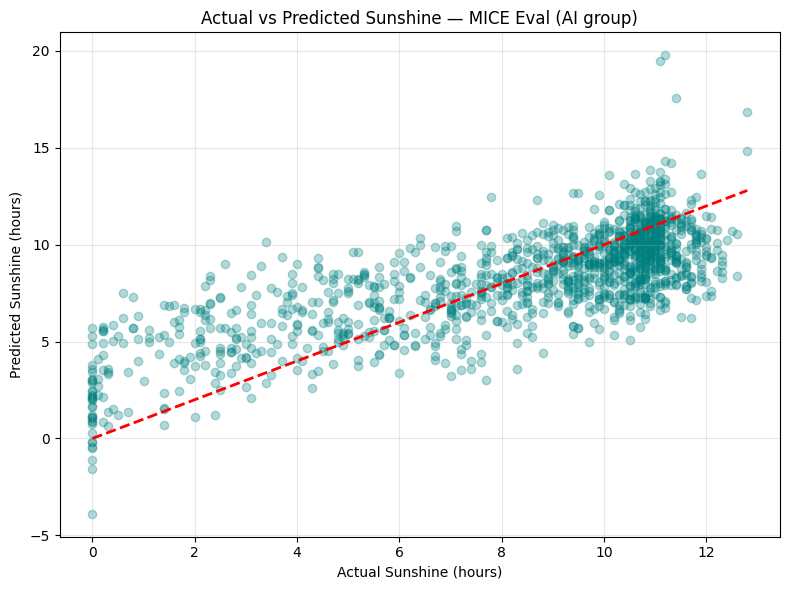

In [5]:
plt.figure(figsize=(8, 6))
plt.scatter(y_true_ai, y_pred_mice, alpha=0.3, color='teal')
plt.plot([y_true_ai.min(), y_true_ai.max()], [y_true_ai.min(), y_true_ai.max()],
         '--r', linewidth=2)
plt.title('Actual vs Predicted Sunshine — MICE Eval (AI group)')
plt.xlabel('Actual Sunshine (hours)')
plt.ylabel('Predicted Sunshine (hours)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
def mice_impute_column(df, groups, cols_for_imputer, target_cols, imputers=None):
    """In-place MICE imputation for target_cols, per group.

    Si `imputers` est None : mode train.
        On ajuste un IterativeImputer par groupe (fit_transform) et on retourne
        le dict {grp: imputer} avec les imputers ajustés.
    Si `imputers` est fourni : mode test.
        On applique transform avec les imputers déjà ajustés sur le train.
    """
    all_cols = [c for c in cols_for_imputer if c not in target_cols] + target_cols
    fit_mode = imputers is None
    if fit_mode:
        imputers = {}
    for grp in groups:
        print(f"  Imputing {target_cols} — group {grp} …")
        mask = df['weather_trend_group'] == grp
        subset = df.loc[mask, all_cols].copy()
        if fit_mode:
            imputer = IterativeImputer(random_state=RANDOM_STATE, max_iter=10)
            imputed = imputer.fit_transform(subset)
            imputers[grp] = imputer
        else:
            imputer = imputers[grp]
            imputed = imputer.transform(subset)
        df_tmp = pd.DataFrame(imputed, columns=all_cols, index=df.loc[mask].index)
        df.loc[mask, target_cols] = df_tmp[target_cols]
    return df, imputers

GROUPS = ['AI', 'CS', 'TP', 'TS']

# Impute Sunshine for all groups
df_train, imputers_sun = mice_impute_column(df_train, GROUPS, COLS_SUN_MICE, ['Sunshine'])

print("\nSunshine nulls after imputation:")
print(df_train['Sunshine'].isnull().groupby(df_train['weather_trend_group']).sum())

  Imputing ['Sunshine'] — group AI …
  Imputing ['Sunshine'] — group CS …
  Imputing ['Sunshine'] — group TP …
  Imputing ['Sunshine'] — group TS …

Sunshine nulls after imputation:
weather_trend_group
AI    0
CS    0
TP    0
TS    0
Name: Sunshine, dtype: int64


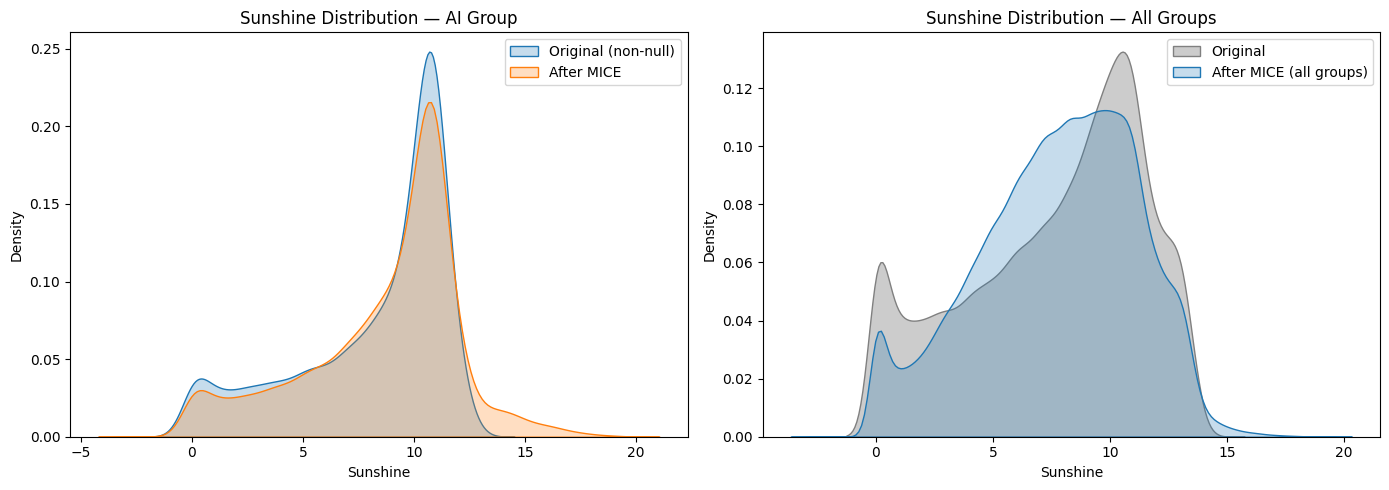

In [7]:
# Distribution before vs after (AI group example)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(df_AI['Sunshine'].dropna(), ax=axes[0], label='Original (non-null)', fill=True)
sns.kdeplot(df_train.loc[df_train['weather_trend_group'] == 'AI', 'Sunshine'],
            ax=axes[0], label='After MICE', fill=True)
axes[0].set_title("Sunshine Distribution — AI Group")
axes[0].legend()

sns.kdeplot(df.loc[df_train.index, 'Sunshine'].dropna(), ax=axes[1], label='Original', fill=True, color='gray', alpha=0.4)
sns.kdeplot(df_train['Sunshine'], ax=axes[1], label='After MICE (all groups)', fill=True)
axes[1].set_title("Sunshine Distribution — All Groups")
axes[1].legend()

plt.tight_layout()
plt.show()

### 3.2. Imputer `Evaporation`, `Cloud9am`, `Cloud3pm`

In [8]:
COLS_CLOUD = ['MinTemp','MaxTemp','Rainfall','Humidity9am','Temp9am',
              'Date_sin','Date_cos','Sunshine',
              'Evaporation','Cloud9am','Cloud3pm']

df_train, imputers_cloud = mice_impute_column(df_train, GROUPS, COLS_CLOUD, ['Evaporation','Cloud9am','Cloud3pm'])
print("Nulls after cloud/evaporation imputation:")
print(df_train[['Evaporation','Cloud9am','Cloud3pm']].isnull().sum())


  Imputing ['Evaporation', 'Cloud9am', 'Cloud3pm'] — group AI …
  Imputing ['Evaporation', 'Cloud9am', 'Cloud3pm'] — group CS …
  Imputing ['Evaporation', 'Cloud9am', 'Cloud3pm'] — group TP …
  Imputing ['Evaporation', 'Cloud9am', 'Cloud3pm'] — group TS …
Nulls after cloud/evaporation imputation:
Evaporation    0
Cloud9am       0
Cloud3pm       0
dtype: int64


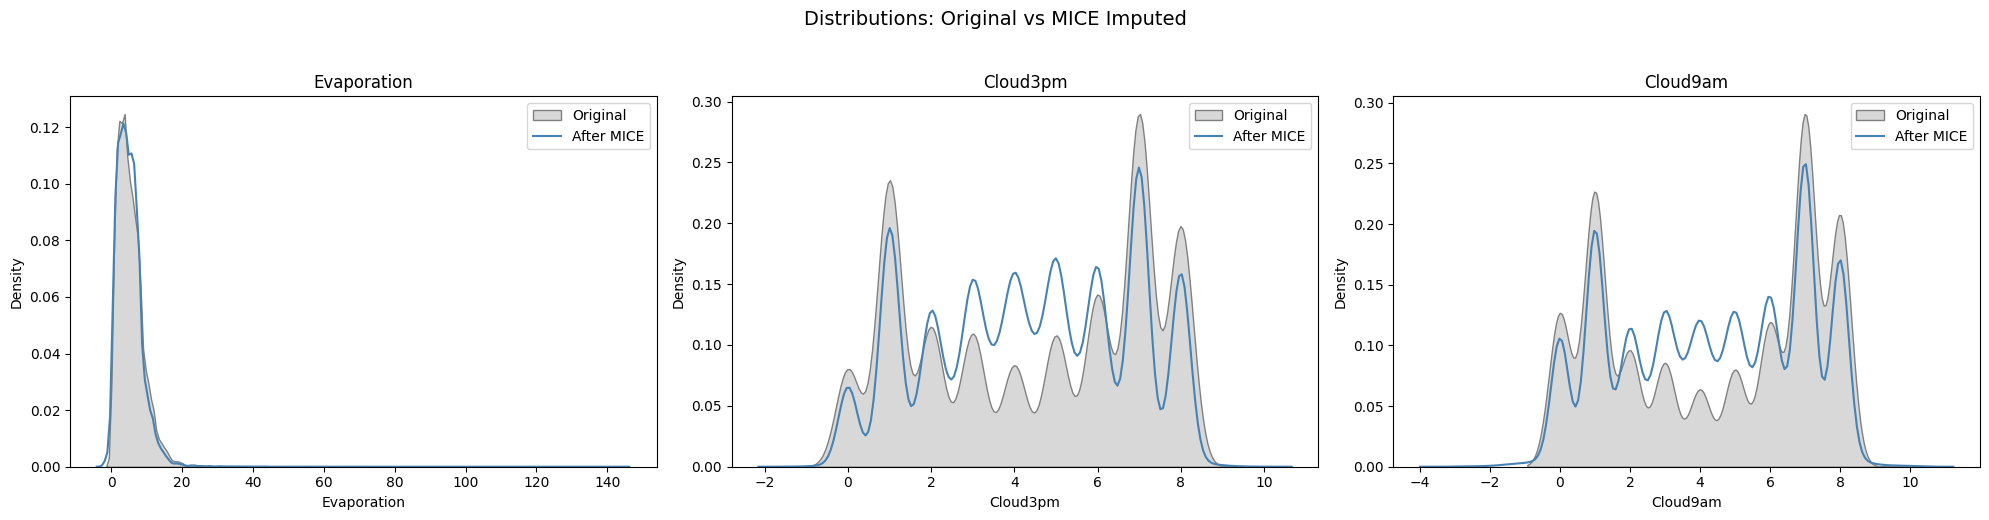

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for i, col in enumerate(['Evaporation','Cloud3pm','Cloud9am']):
    sns.kdeplot(df.loc[df_train.index, col].dropna(), ax=axes[i],
                label='Original', fill=True, color='gray', alpha=0.3)
    sns.kdeplot(df_train[col], ax=axes[i], label='After MICE', color='steelblue')
    axes[i].set_title(f'{col}')
    axes[i].legend()
plt.suptitle('Distributions: Original vs MICE Imputed', y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

### 3.3. Imputer `Pressure9am` et `Pressure3pm`

In [10]:
COLS_PRESSURE = ['MinTemp','MaxTemp','Rainfall','Humidity9am','Temp9am',
                 'Date_sin','Date_cos',
                 'Sunshine','Evaporation','Cloud9am','Cloud3pm',
                 'Pressure9am','Pressure3pm']

df_train, imputers_pressure = mice_impute_column(df_train, GROUPS, COLS_PRESSURE, ['Pressure9am','Pressure3pm'])
print("Nulls after pressure imputation:")
print(df_train[['Pressure9am','Pressure3pm']].isnull().sum())


  Imputing ['Pressure9am', 'Pressure3pm'] — group AI …
  Imputing ['Pressure9am', 'Pressure3pm'] — group CS …


/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


  Imputing ['Pressure9am', 'Pressure3pm'] — group TP …
  Imputing ['Pressure9am', 'Pressure3pm'] — group TS …
Nulls after pressure imputation:
Pressure9am    0
Pressure3pm    0
dtype: int64


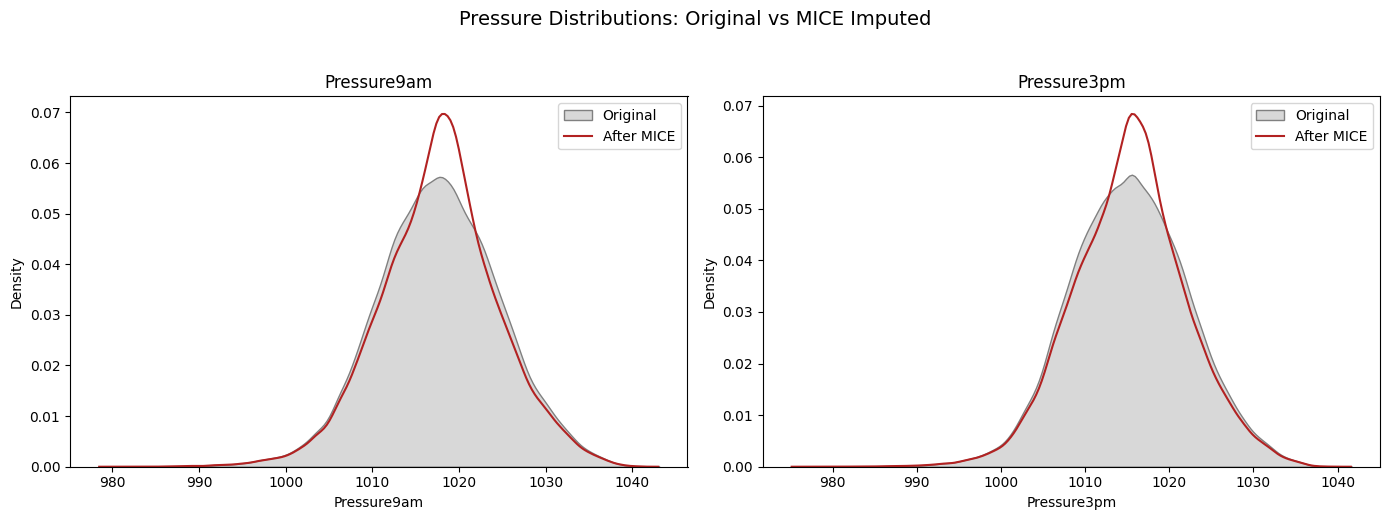

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, col in enumerate(['Pressure9am','Pressure3pm']):
    sns.kdeplot(df.loc[df_train.index, col].dropna(), ax=axes[i],
                label='Original', fill=True, color='gray', alpha=0.3)
    sns.kdeplot(df_train[col], ax=axes[i], label='After MICE', color='firebrick')
    axes[i].set_title(f'{col}')
    axes[i].legend()
plt.suptitle('Pressure Distributions: Original vs MICE Imputed', y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

### 3.4. Imputer la vitesse du vent (KNN) et la direction du vent (sin/cos cyclique + KNN)

Les directions du vent sont **cycliques** : N (0°) est plus proche de NW (315°) que de S (180°).  
Un encodage simple d'étiquette ou ordinal créerait une fausse distance entre N et NW.  

**Stratégie**
1. Mapper la rose des vents à 16 points en degrés (0°–360°).
2. Encoder chaque colonne de direction sous forme de composantes **sin** et **cos** → deux caractéristiques continues qui préservent la proximité cyclique.
3. Imputer les valeurs sin/cos manquantes avec **KNN** (aux côtés des prédicteurs météorologiques numériques).
4. Décoder les sin/cos imputés en label de compass le plus proche.
5. Garder la colonne de chaîne d'origine mise à jour **et** éventuellement conserver les colonnes sin/cos pour la modélisation.

In [12]:
WIND_SPEED_COLS = ['WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm']
WIND_DIR_COLS   = ['WindGustDir',   'WindDir9am',   'WindDir3pm']

# 16-point compass rose → degrees
COMPASS_DEGREES = {
    'N': 0, 'NNE': 22.5, 'NE': 45,  'ENE': 67.5,
    'E': 90, 'ESE': 112.5, 'SE': 135, 'SSE': 157.5,
    'S': 180, 'SSW': 202.5, 'SW': 225, 'WSW': 247.5,
    'W': 270, 'WNW': 292.5, 'NW': 315, 'NNW': 337.5
}
# Reverse map: degrees → label (used when decoding)
DEGREES_COMPASS = {v: k for k, v in COMPASS_DEGREES.items()}
COMPASS_ARRAY   = np.array(sorted(DEGREES_COMPASS.keys()))   # [0, 22.5, 45, …]

def encode_cyclic(series: pd.Series) -> pd.DataFrame:
    """Map compass labels → sin/cos pair. NaN stays NaN."""
    deg = series.map(COMPASS_DEGREES)                         # str → float degrees
    rad = np.deg2rad(deg)
    return pd.DataFrame(
        {'sin': np.sin(rad), 'cos': np.cos(rad)},
        index=series.index
    )

def decode_cyclic(sin_vals: pd.Series, cos_vals: pd.Series) -> pd.Series:
    """Recover the nearest compass label from imputed sin/cos values."""
    angles = np.rad2deg(np.arctan2(sin_vals, cos_vals)) % 360
    # Find closest degree in the compass rose
    def nearest_label(a):
        idx = np.argmin(np.abs(COMPASS_ARRAY - a))
        return DEGREES_COMPASS[COMPASS_ARRAY[idx]]
    return angles.map(nearest_label)

print("Compass encoding helpers defined.")
print("Example — N:", encode_cyclic(pd.Series(['N'])).round(4).to_dict('records'))
print("Example — NW:", encode_cyclic(pd.Series(['NW'])).round(4).to_dict('records'))

Compass encoding helpers defined.
Example — N: [{'sin': 0.0, 'cos': 1.0}]
Example — NW: [{'sin': -0.7071, 'cos': 0.7071}]


In [13]:
# ── Step 1: encode all wind direction columns as sin/cos ──────────────────────
for col in WIND_DIR_COLS:
    enc = encode_cyclic(df_train[col])
    df_train[f'{col}_sin'] = enc['sin']
    df_train[f'{col}_cos'] = enc['cos']

WIND_DIR_SIN_COS = [f'{c}_{t}' for c in WIND_DIR_COLS for t in ('sin','cos')]
print("Cyclic columns created:", WIND_DIR_SIN_COS)
print("Missing before imputation:")
print(df_train[WIND_DIR_SIN_COS].isnull().sum())

Cyclic columns created: ['WindGustDir_sin', 'WindGustDir_cos', 'WindDir9am_sin', 'WindDir9am_cos', 'WindDir3pm_sin', 'WindDir3pm_cos']
Missing before imputation:
WindGustDir_sin    6860
WindGustDir_cos    6860
WindDir9am_sin     7318
WindDir9am_cos     7318
WindDir3pm_sin     2597
WindDir3pm_cos     2597
dtype: int64


In [14]:
# ── Step 2: MICE imputation per group ────────────────────────────────────────
# Feature set: numeric predictors + wind speeds + sin/cos direction components
MICE_DIR_FEATURES = (['MinTemp','MaxTemp','Rainfall','Humidity9am','Temp9am',
                      'Sunshine','Pressure9am','Pressure3pm']
                     + WIND_SPEED_COLS
                     + WIND_DIR_SIN_COS)

imputers_wind = {}
for grp in GROUPS:
    mask = df_train['weather_trend_group'] == grp
    g    = df_train.loc[mask, MICE_DIR_FEATURES].copy()

    mice = IterativeImputer(random_state=RANDOM_STATE, max_iter=10)
    imp_data = mice.fit_transform(g)
    imputers_wind[grp] = mice
    df_tmp = pd.DataFrame(imp_data, columns=MICE_DIR_FEATURES, index=g.index)

    # Write back wind speeds
    df_train.loc[mask, WIND_SPEED_COLS] = df_tmp[WIND_SPEED_COLS]
    # Write back sin/cos components
    df_train.loc[mask, WIND_DIR_SIN_COS] = df_tmp[WIND_DIR_SIN_COS]

print("Missing sin/cos after MICE imputation:")
print(df_train[WIND_DIR_SIN_COS].isnull().sum())

Missing sin/cos after MICE imputation:
WindGustDir_sin    0
WindGustDir_cos    0
WindDir9am_sin     0
WindDir9am_cos     0
WindDir3pm_sin     0
WindDir3pm_cos     0
dtype: int64


In [15]:
# ── Step 3: decode sin/cos → nearest compass label ───────────────────────────
for col in WIND_DIR_COLS:
    df_train[col] = decode_cyclic(df_train[f'{col}_sin'], df_train[f'{col}_cos'])

print("Missing direction labels after decode:")
print(df_train[WIND_DIR_COLS].isnull().sum())
print("\nSample value counts — WindGustDir:")
print(df_train['WindGustDir'].value_counts().head(8))

Missing direction labels after decode:
WindGustDir    0
WindDir9am     0
WindDir3pm     0
dtype: int64

Sample value counts — WindGustDir:
WindGustDir
SE     8148
W      8119
E      7620
SSE    7501
WSW    7442
S      7383
SW     7354
N      7227
Name: count, dtype: int64


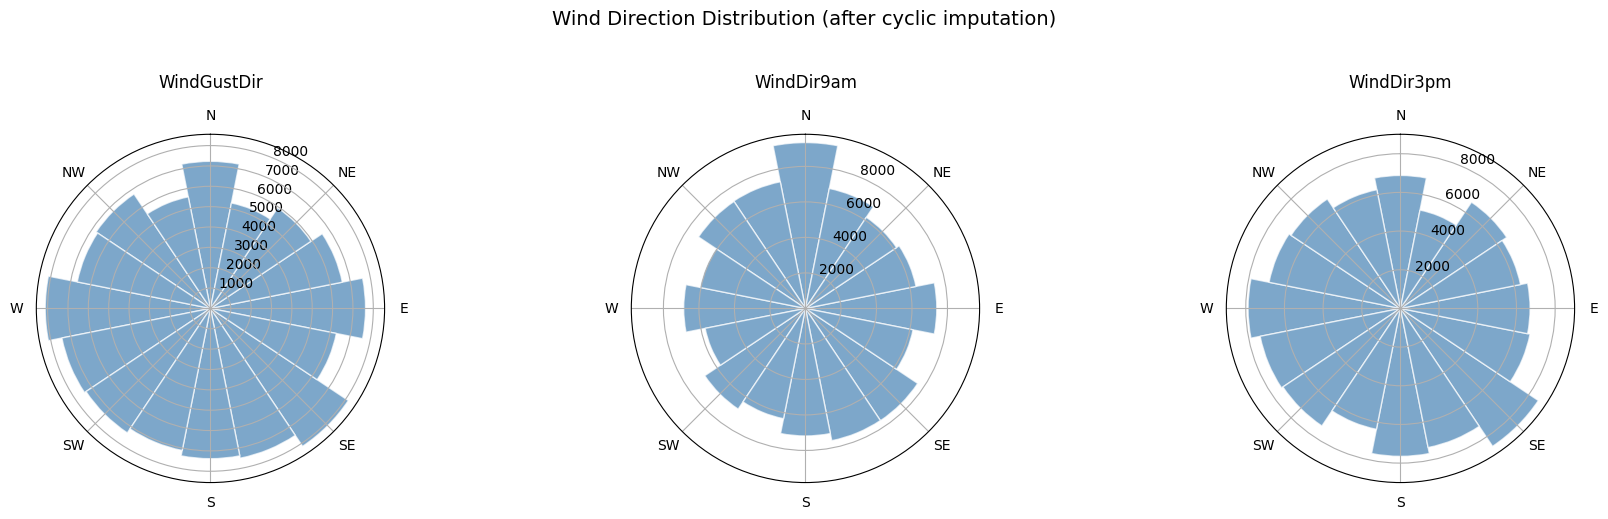


All wind nulls after imputation:
WindGustSpeed    0
WindSpeed9am     0
WindSpeed3pm     0
WindGustDir      0
WindDir9am       0
WindDir3pm       0
dtype: int64


In [16]:
# ── Step 4: validate cyclic encoding with a polar plot ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5),
                          subplot_kw=dict(projection='polar'))

for ax, col in zip(axes, WIND_DIR_COLS):
    counts = df_train[col].value_counts()
    labels = counts.index.tolist()
    angles = np.deg2rad([COMPASS_DEGREES[l] for l in labels])
    bars   = ax.bar(angles, counts.values, width=np.deg2rad(22.5),
                    bottom=0, alpha=0.7, color='steelblue', edgecolor='white')
    ax.set_theta_zero_location('N')   # North at top
    ax.set_theta_direction(-1)        # clockwise
    ax.set_xticks(np.deg2rad([0,45,90,135,180,225,270,315]))
    ax.set_xticklabels(['N','NE','E','SE','S','SW','W','NW'])
    ax.set_title(col, pad=15)

plt.suptitle('Wind Direction Distribution (after cyclic imputation)', y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

print("\nAll wind nulls after imputation:")
print(df_train[WIND_SPEED_COLS + WIND_DIR_COLS].isnull().sum())

### 3.5. Imputer les colonnes résiduelles : `Humidity3pm` et `Temp3pm`

In [17]:
COLS_RESIDUAL = ['MinTemp','MaxTemp','Rainfall','Humidity9am','Temp9am',
                 'Date_sin','Date_cos',
                 'Sunshine','Evaporation','Cloud9am','Cloud3pm',
                 'Pressure9am','Pressure3pm',
                 'Humidity3pm','Temp3pm']

df_train, imputers_residual = mice_impute_column(df_train, GROUPS, COLS_RESIDUAL, ['Humidity3pm','Temp3pm'])

print("\nFinal missing-value summary:")
miss = df_train.isnull().sum()
display(miss[miss > 0].to_frame('nulls'))


  Imputing ['Humidity3pm', 'Temp3pm'] — group AI …
  Imputing ['Humidity3pm', 'Temp3pm'] — group CS …
  Imputing ['Humidity3pm', 'Temp3pm'] — group TP …
  Imputing ['Humidity3pm', 'Temp3pm'] — group TS …

Final missing-value summary:


,nulls


### 3.6. Application des imputers ajustés sur le train au jeu de test

On applique exactement la même séquence d'imputations sur `df_test`, mais en mode `transform` (les imputers ont été ajustés sur le train uniquement).

In [18]:
# Imputation : Sunshine
df_test, _ = mice_impute_column(df_test, GROUPS, COLS_SUN_MICE, ['Sunshine'], imputers=imputers_sun)
print("Test — Sunshine nulls after imputation:")
print(df_test['Sunshine'].isnull().groupby(df_test['weather_trend_group']).sum())

  Imputing ['Sunshine'] — group AI …
  Imputing ['Sunshine'] — group CS …
  Imputing ['Sunshine'] — group TP …
  Imputing ['Sunshine'] — group TS …
Test — Sunshine nulls after imputation:
weather_trend_group
AI    0
CS    0
TP    0
TS    0
Name: Sunshine, dtype: int64


In [19]:
# Imputation : Evaporation, Cloud9am, Cloud3pm
df_test, _ = mice_impute_column(df_test, GROUPS, COLS_CLOUD, ['Evaporation','Cloud9am','Cloud3pm'], imputers=imputers_cloud)
print("Test — Nulls after cloud/evaporation imputation:")
print(df_test[['Evaporation','Cloud9am','Cloud3pm']].isnull().sum())

  Imputing ['Evaporation', 'Cloud9am', 'Cloud3pm'] — group AI …
  Imputing ['Evaporation', 'Cloud9am', 'Cloud3pm'] — group CS …
  Imputing ['Evaporation', 'Cloud9am', 'Cloud3pm'] — group TP …
  Imputing ['Evaporation', 'Cloud9am', 'Cloud3pm'] — group TS …
Test — Nulls after cloud/evaporation imputation:
Evaporation    0
Cloud9am       0
Cloud3pm       0
dtype: int64


In [20]:
# Imputation : Pressure9am, Pressure3pm
df_test, _ = mice_impute_column(df_test, GROUPS, COLS_PRESSURE, ['Pressure9am','Pressure3pm'], imputers=imputers_pressure)
print("Test — Nulls after pressure imputation:")
print(df_test[['Pressure9am','Pressure3pm']].isnull().sum())

  Imputing ['Pressure9am', 'Pressure3pm'] — group AI …
  Imputing ['Pressure9am', 'Pressure3pm'] — group CS …
  Imputing ['Pressure9am', 'Pressure3pm'] — group TP …
  Imputing ['Pressure9am', 'Pressure3pm'] — group TS …
Test — Nulls after pressure imputation:
Pressure9am    0
Pressure3pm    0
dtype: int64


In [21]:
# Imputation : Vent
# Step 1: encode sin/cos
for col in WIND_DIR_COLS:
    enc = encode_cyclic(df_test[col])
    df_test[f'{col}_sin'] = enc['sin']
    df_test[f'{col}_cos'] = enc['cos']

# Step 2: MICE transform par groupe (imputers ajustés sur le train)
for grp in GROUPS:
    mask = df_test['weather_trend_group'] == grp
    g    = df_test.loc[mask, MICE_DIR_FEATURES].copy()
    imp_data = imputers_wind[grp].transform(g)
    df_tmp = pd.DataFrame(imp_data, columns=MICE_DIR_FEATURES, index=g.index)
    df_test.loc[mask, WIND_SPEED_COLS]  = df_tmp[WIND_SPEED_COLS]
    df_test.loc[mask, WIND_DIR_SIN_COS] = df_tmp[WIND_DIR_SIN_COS]

# Step 3: decode sin/cos -> labels
for col in WIND_DIR_COLS:
    df_test[col] = decode_cyclic(df_test[f'{col}_sin'], df_test[f'{col}_cos'])

print("Test — All wind nulls after imputation:")
print(df_test[WIND_SPEED_COLS + WIND_DIR_COLS].isnull().sum())

Test — All wind nulls after imputation:
WindGustSpeed    0
WindSpeed9am     0
WindSpeed3pm     0
WindGustDir      0
WindDir9am       0
WindDir3pm       0
dtype: int64


In [22]:
# Imputation : Humidity3pm, Temp3pm
df_test, _ = mice_impute_column(df_test, GROUPS, COLS_RESIDUAL, ['Humidity3pm','Temp3pm'], imputers=imputers_residual)

print("\nTest — Final missing-value summary:")
miss_test = df_test.isnull().sum()
display(miss_test[miss_test > 0].to_frame('nulls'))

  Imputing ['Humidity3pm', 'Temp3pm'] — group AI …
  Imputing ['Humidity3pm', 'Temp3pm'] — group CS …
  Imputing ['Humidity3pm', 'Temp3pm'] — group TP …
  Imputing ['Humidity3pm', 'Temp3pm'] — group TS …

Test — Final missing-value summary:


,nulls


### 3.7. Validation finale

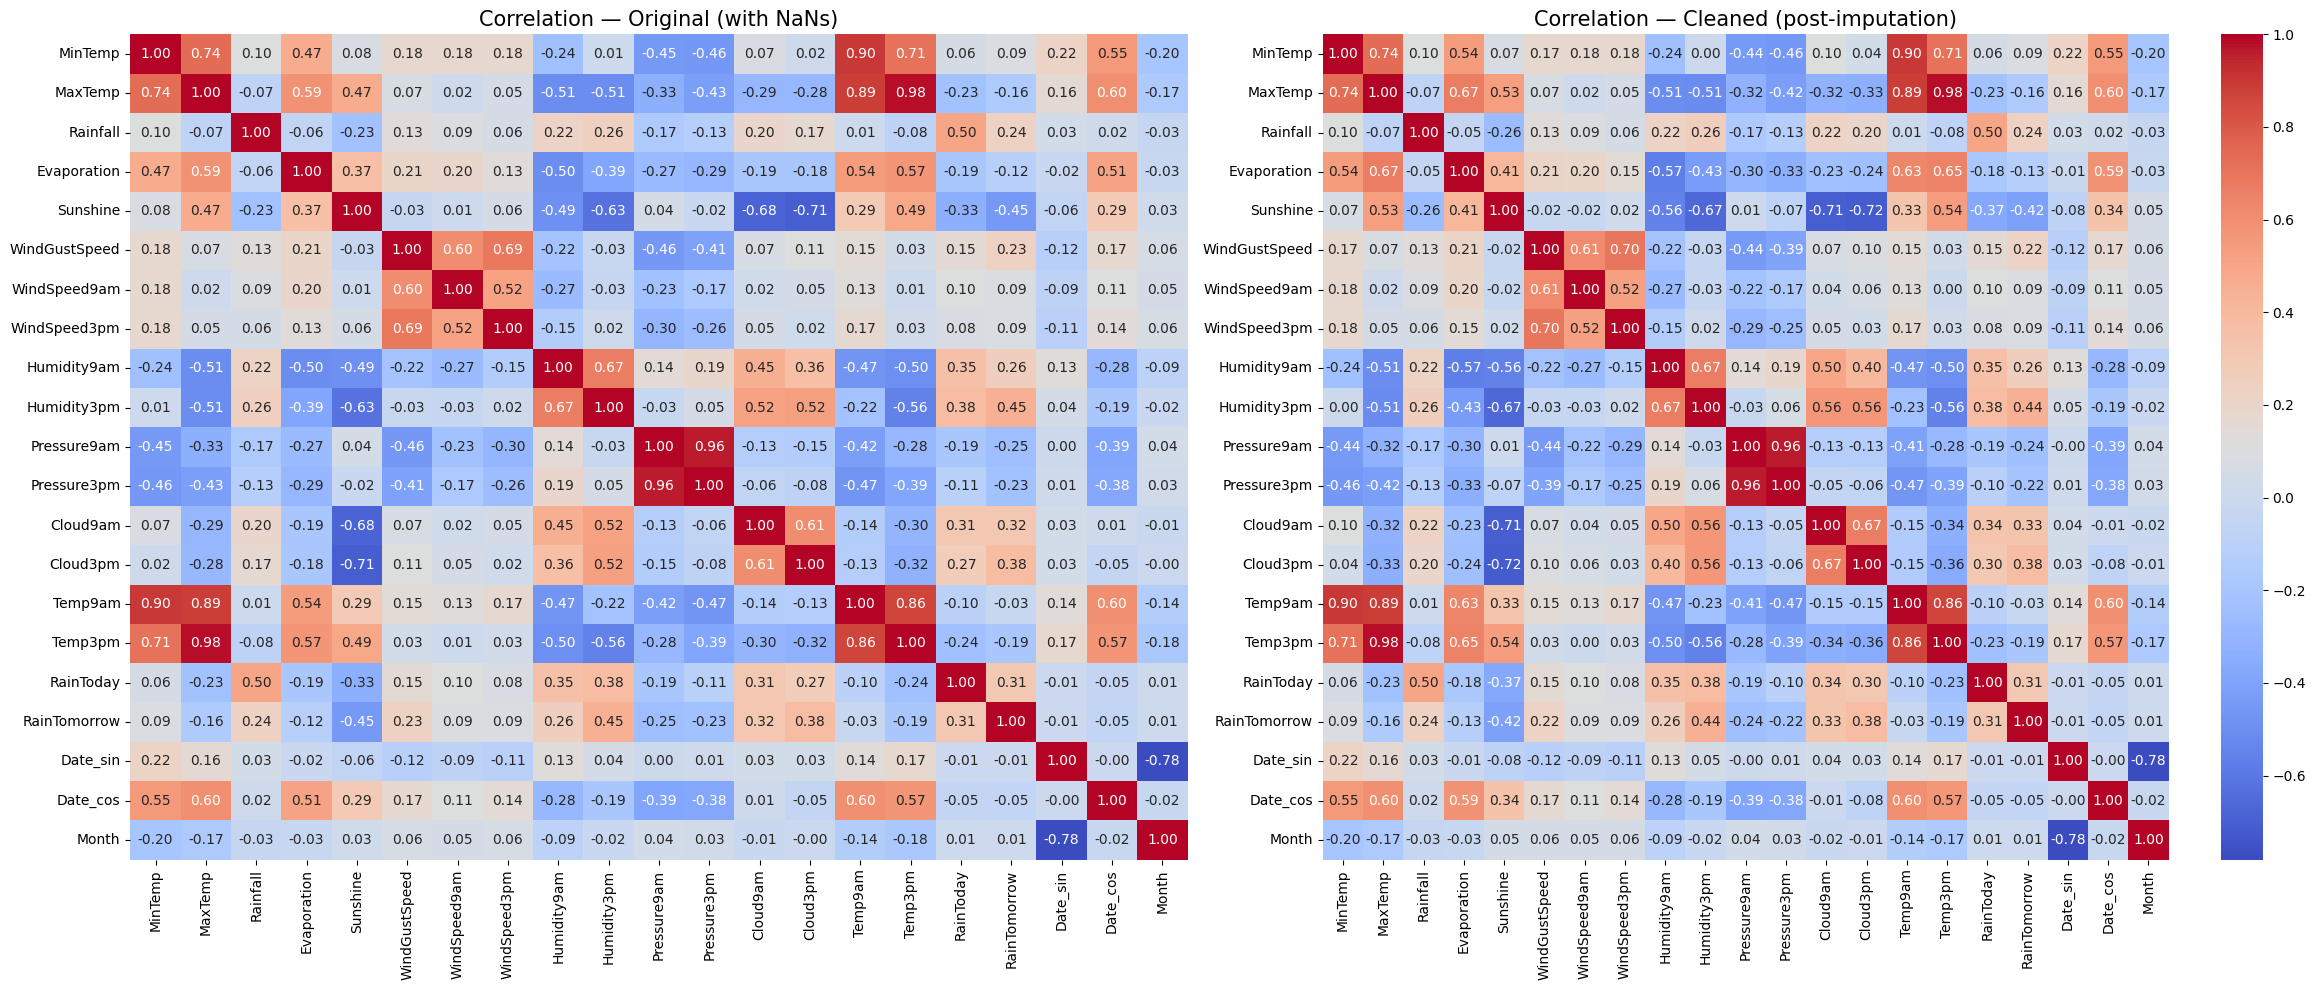

Max correlation change after imputation:
Evaporation    0.088636
Temp9am        0.088636
MaxTemp        0.082101
Date_cos       0.080346
MinTemp        0.078647
Temp3pm        0.078135
Humidity9am    0.063221
Cloud3pm       0.063027
Cloud9am       0.063027
Sunshine       0.061293
dtype: float64


In [23]:
num_cols = df_train.select_dtypes(include=['float64','int64','bool']).columns
num_cols_raw = df.select_dtypes(include=['float64','int64','bool']).columns

fig, axes = plt.subplots(1, 2, figsize=(24, 10))
sns.heatmap(df.loc[df_train.index, num_cols_raw].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', ax=axes[0], cbar=False)
axes[0].set_title('Correlation — Original (with NaNs)', fontsize=15)

sns.heatmap(df_train.loc[df_train.index, num_cols_raw].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1])
axes[1].set_title('Correlation — Cleaned (post-imputation)', fontsize=15)

plt.tight_layout()
plt.show()

corr_diff = (df_train[num_cols].corr() - df.loc[df_train.index, num_cols_raw].corr()).abs()
print("Max correlation change after imputation:")
print(corr_diff.max().sort_values(ascending=False).head(10))

In [24]:
print(f"Final DataFrame shape: {df_train.shape}")
print(f"Total nulls remaining: {df_train.isnull().sum().sum()}")
df_train.head()

Final DataFrame shape: (111056, 33)
Total nulls remaining: 0


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Date_sin,Date_cos,weather_trend_group,Month,WindGustDir_sin,WindGustDir_cos,WindDir9am_sin,WindDir9am_cos,WindDir3pm_sin,WindDir3pm_cos
46871,2010-02-17,Tuggeranong,11.6,27.5,0.0,6.030695,9.544657,E,28.0,SSE,...,0.735034,0.678031,CS,2,1.000000,6.123234e-17,0.382683,-0.923880,-0.923880,0.382683
120618,2017-02-17,SalmonGums,12.8,23.8,0.0,7.233429,9.407523,SE,31.0,SSE,...,0.735034,0.678031,TS,2,0.707107,-7.071068e-01,0.382683,-0.923880,0.382683,-0.923880
116417,2013-09-04,Perth,11.7,18.5,11.2,4.600000,10.200000,WNW,39.0,WSW,...,-0.894542,-0.446983,TS,9,-0.923880,3.826834e-01,-0.923880,-0.382683,-0.923880,-0.382683
219,2009-07-10,Albury,0.1,13.5,0.0,0.057172,6.556589,E,13.0,ESE,...,-0.143572,-0.989640,CS,7,1.000000,6.123234e-17,0.507352,-0.275094,0.382683,-0.923880
59588,2013-11-05,Sale,3.6,19.5,0.0,6.000000,12.700000,ESE,33.0,WNW,...,-0.823547,0.567248,CS,11,0.923880,-3.826834e-01,-0.923880,0.382683,0.923880,-0.382683


---
## 4. Transformation des features

### 4.1. Encodage des variables catégorielles

In [25]:
cat_cols = df_train.select_dtypes(include=['object', 'bool']).columns.difference(['Date', 'RainTomorrow'])
print(f"Colonnes catégorielles : {list(cat_cols)}")

le = LabelEncoder()
for col in cat_cols:
    df_train[col] = le.fit_transform(df_train[col].astype(str))
    df_test[col] = le.transform(df_test[col].astype(str))

Colonnes catégorielles : ['Location', 'RainToday', 'WindDir3pm', 'WindDir9am', 'WindGustDir', 'weather_trend_group']


/tmp/ipykernel_17423/3109472179.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_train.select_dtypes(include=['object', 'bool']).columns.difference(['Date', 'RainTomorrow'])


NameError: name 'LabelEncoder' is not defined

### 4.2. Scaling avec RobustScaler

In [ ]:
COLS_TO_SCALE = [
    'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
    'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm',
    'Humidity9am', 'Humidity3pm',
    'Pressure9am', 'Pressure3pm',
    'Cloud9am', 'Cloud3pm',
    'Temp9am', 'Temp3pm'
]

scaler = RobustScaler()

df_train[COLS_TO_SCALE] = scaler.fit_transform(df_train[COLS_TO_SCALE])
df_test[COLS_TO_SCALE] = scaler.transform(df_test[COLS_TO_SCALE])

print("Scaling appliqué. Aperçu des stats sur le train :")
display(df_train[COLS_TO_SCALE].describe().T[['mean', '50%', 'std', 'min', 'max']].round(3))

Scaling appliqué. Aperçu des stats sur le train :


,mean,50%,std,min,max
MinTemp,0.023,0.0,0.688,-2.204,2.355
MaxTemp,0.055,0.0,0.689,-2.670,2.466
Rainfall,2.944,0.0,10.592,0.000,463.750
Evaporation,0.101,-0.0,0.848,-1.749,31.878
Sunshine,-0.067,0.0,0.697,-2.204,2.330
WindGustSpeed,0.057,0.0,0.793,-1.930,5.798
WindSpeed9am,0.083,0.0,0.739,-1.365,9.750
WindSpeed3pm,-0.032,0.0,0.797,-1.727,6.631
Humidity9am,-0.044,0.0,0.734,-2.692,1.154
Humidity3pm,-0.018,0.0,0.715,-1.912,1.655


---
## 4. Export

In [ ]:
TRAIN_OUTPUT_PATH = "../data/weatherAUS_train.csv"
df_train.to_csv(TRAIN_OUTPUT_PATH, index=False)
print(f"Saved → {TRAIN_OUTPUT_PATH}  ({df_train.shape[0]:,} rows x {df_train.shape[1]} cols)")

TEST_OUTPUT_PATH = "../data/weatherAUS_test.csv"
df_test.to_csv(TEST_OUTPUT_PATH, index=False)
print(f"Saved → {TEST_OUTPUT_PATH}  ({df_test.shape[0]:,} rows x {df_test.shape[1]} cols)")

Saved → ../data/weatherAUS_train.csv  (111,056 rows x 33 cols)
Saved → ../data/weatherAUS_test.csv  (27,764 rows x 33 cols)
